# Plot showing damage functions with regression uncertainty

In [1]:
import xarray as xr
import xagg as xa
import numpy as np
import pandas as pd
import geopandas as gpd
import os
import re
import glob
import string
import zarr
import warnings
from tqdm.notebook import tqdm

import matplotlib as mpl
from matplotlib import pyplot as plt

from funcs_support import get_filepaths,get_params,utility_save,utility_print
from funcs_readregs import coeffs_mortality, coeffs_gdppc, coeffs_payroll

dir_list = get_params()



In [2]:
params_proc = {'mortality':{'varname':'tassumpoly','geo_typ':'impact-regions','popwght':False},
               'gdppc':{'varname':'tassumpoly','geo_typ':'adm1','popwght':True},
               'payroll':{'varname':'days90plus','geo_typ':'adm2-us','popwght':True}}

nsamples = 1000
rng = np.random.default_rng()

In [3]:
def get_coeff_draws(proc,load_kwargs = {},
                    rng = rng,
                    nsamples = nsamples):
    ''' Get MC draws of coefficients

    Parameters
    ---------------
    proc : str
        Name of impact variable

    load_kwargs : dict
        Piped into `coeffs_*()`

    rng : numpy random generator

    nsamples : int
        Number of MC samples of VCV to use

    Returns
    ---------------
    coeffs_mvn : xr.DataArray
    '''

    # Load regression coefficients
    if proc == 'gdppc':
        coeffs,vcv = coeffs_gdppc(**load_kwargs)
    elif proc == 'mortality':
        coeffs,vcv = coeffs_mortality(**load_kwargs)
    elif proc == 'payroll':
        coeffs,vcv = coeffs_payroll(**load_kwargs)
    else:
        raise KeyError()

    coeffs = coeffs.dropna('proj_base',how='all')
    if 'proj_base_1' in vcv:
        vcv.dropna('proj_base_1').dropna('proj_base_2')
    else:
        vcv = vcv.dropna('proj_base',how='all')

    # Get MC samples of coefficients
    if 'proj_base_1' in vcv:
        # If jointly estimated across parameters
        coeffs_tmp = coeffs.coeffs.stack(predproj = ['pred','proj_base'])
        vcv_tmp = vcv.vcv.stack(predproj_1 = ['pred_1','proj_base_1'],
                                 predproj_2 = ['pred_2','proj_base_2'])
        
        coeffs_mvn = rng.multivariate_normal(coeffs_tmp,
                                             vcv_tmp,
                                             size=nsamples)
        
        coeffs_mvn = xr.DataArray(coeffs_mvn,
                                  dims = ['sidx','predproj'],
                                  coords = {'predproj':coeffs_tmp.predproj})
        coeffs_mvn = coeffs_mvn.unstack('predproj')
    else:
        # If separate fit for each proj_base
        coeffs_mvn = xr.apply_ufunc(rng.multivariate_normal,
                                   coeffs.coeffs,
                                   vcv.vcv,
                                   input_core_dims = [['pred'],['pred_1','pred_2']],
                                   output_core_dims = [['sidx','pred']],
                                   kwargs = {'size':nsamples},
                                           dask = 'parallelized',
                                           dask_gufunc_kwargs = {'output_sizes':{'sidx':nsamples}},
                                   vectorize=True)
    return coeffs_mvn

In [4]:
def load_dmgfs(proc,load_kwargs = {},
              rng = rng,
              nsamples = nsamples):
    ''' Load MC'ed damage function, sampled at temperatures Tref

    Parameters
    ---------------
    proc : str
        Name of impact variable

    load_kwargs : dict
        Piped into `coeffs_*()`

    rng : numpy random generator

    nsamples : int
        Number of MC samples of VCV to use

    Returns
    ---------------
    dmgf : xr.DataArray
        `Tref` x `proj_base` x `sidx` datarray giving 
        coefficients at temperatures `Tref`


    '''
    
    # Load regression coefficients
    if proc == 'gdppc':
        coeffs,vcv = coeffs_gdppc(**load_kwargs)
    elif proc == 'mortality':
        coeffs,vcv = coeffs_mortality(**load_kwargs)
    elif proc == 'payroll':
        coeffs,vcv = coeffs_payroll(**load_kwargs)
    else:
        raise KeyError()

    coeffs = coeffs.dropna('proj_base',how='all')
    if 'proj_base_1' in vcv:
        vcv.dropna('proj_base_1').dropna('proj_base_2')
    else:
        vcv = vcv.dropna('proj_base',how='all')

    # Get MC samples of coefficients
    if 'proj_base_1' in vcv:
        # If jointly estimated across parameters
        coeffs_tmp = coeffs.coeffs.stack(predproj = ['pred','proj_base'])
        vcv_tmp = vcv.vcv.stack(predproj_1 = ['pred_1','proj_base_1'],
                                 predproj_2 = ['pred_2','proj_base_2'])
        
        coeffs_mvn = rng.multivariate_normal(coeffs_tmp,
                                             vcv_tmp,
                                             size=nsamples)
        
        coeffs_mvn = xr.DataArray(coeffs_mvn,
                                  dims = ['sidx','predproj'],
                                  coords = {'predproj':coeffs_tmp.predproj})
        coeffs_mvn = coeffs_mvn.unstack('predproj')
    else:
        # If separate fit for each proj_base
        coeffs_mvn = xr.apply_ufunc(rng.multivariate_normal,
                                   coeffs.coeffs,
                                   vcv.vcv,
                                   input_core_dims = [['pred'],['pred_1','pred_2']],
                                   output_core_dims = [['sidx','pred']],
                                   kwargs = {'size':nsamples},
                                           dask = 'parallelized',
                                           dask_gufunc_kwargs = {'output_sizes':{'sidx':nsamples}},
                                   vectorize=True)

    if np.any(['sumpoly' in k for k in coeffs_mvn.pred.values]):
        ts = np.arange(-20,51)
        var_stem = 'tassumpoly_'
        poly_degs = [int(re.split(var_stem,v)[-1]) for v in coeffs_mvn.pred.values if var_stem in v]
        t_vals = xr.DataArray(np.vstack([ts**k for k in poly_degs]),
                     dims = ['pred','bin_c'],
                     coords = {'pred':[v for v in coeffs_mvn.pred.values if var_stem in v],
                               'bin_c':ts})
    
        # Get damage function
        dmgf = (coeffs_mvn*t_vals).sum('pred')
        
        if proc == 'mortality':
            # Normalize over lowest value
            dmgf = dmgf - dmgf.sel(bin_c = slice(10,30)).min('bin_c')
        elif proc == 'gdppc':
            # Normalize over highest value
            dmgf = dmgf - dmgf.sel(bin_c = slice(10,30)).max('bin_c')
            #dmgf = dmgf - dmgf.sel(bin_c = 13)
        
        dmgf = dmgf.rename({'bin_c':'Tref'})
    elif 'bin' in coeffs_mvn.pred.values[0]:
        # Constructing the single-bin version
        dmgf = xr.apply_ufunc(rng.normal,
                   coeffs.isel(pred=0),
                   vcv.vcv.isel(pred_1 = 0,pred_2 = 0),
                   output_core_dims = [['sidx']],
                   vectorize=True,
                   kwargs = {'size':nsamples})
        
        dmgf = dmgf.expand_dims({'bin_f':np.arange(float(re.split(r'tasmaxbinF\_',str(coeffs.pred.values[0]))[-1]),
                                             125,5)})
        
        dmgf = xr.concat([xr.zeros_like(dmgf.isel(bin_f=0,drop=True)).expand_dims({'bin_f':np.arange(float(re.split(r'tasmaxbinF\_',str(coeffs.pred.values[0]))[-1])-20,
                                                                                   float(re.split(r'tasmaxbinF\_',str(coeffs.pred.values[0]))[-1]),
                                                                                   5)}),
                          dmgf],
                         dim='bin_f')
    
        dmgf = dmgf.rename({'bin_f':'Tref'}).coeffs
    elif 'days' in coeffs_mvn.pred.values[0]:
        dmgf = coeffs_mvn.expand_dims({'bin_f':np.arange(92.5, 125,5)}).isel(pred=0)
        dmgf = xr.concat([xr.zeros_like(dmgf.isel(bin_f=0,drop=True)).expand_dims({'bin_f':np.arange(92.5-20,
                                                                                           92.5,
                                                                                           5)}),
                                  dmgf],
                                 dim='bin_f')
        dmgf = dmgf.rename({'bin_f':'Tref'})

    return dmgf

In [5]:
colors = {'ERA5':'tab:red','JRA-3Q':'tab:orange','MERRA2':'tab:green','GMFD':'tab:blue','PRISM':'yellow','UDel':'yellow'}

proc_names = {'mortality':'mortality rate [/100,000]',
              'gdppc':'log GDP per capita growth',
              'payroll':'payroll'}
proc_titles = {'mortality':'annual mortality rate',
               'gdppc':'GDP per capita growth',
               'payroll':'annual payroll'}
proc_xlims = {'mortality':[-15,45],
              'gdppc':[-2.5,32.5],
              'payroll':[70,115]}
proc_ylims = {'mortality':[-1,8],
              'gdppc':[-0.375,0.025],
              'payroll':[-0.00075,0.0001]}

In [6]:
def plot_dmgfs(dmgf,proc,ax=None,
               colors = colors,
               add_grid = True,
               proc_names = proc_names,
               proc_titles = proc_titles,
               proc_xlims = proc_xlims,
               proc_ylims = proc_ylims,
               simple = False):
    '''
    Damage function plotting code 

    '''

    if ax is None:
        ax = plt.subplot()
    
    for proj_base in dmgf.proj_base.values:
        plot_data = dmgf.sel(proj_base = proj_base)
        ax.fill_between(plot_data.Tref,
                        plot_data.quantile(0.025,dim='sidx'),
                        plot_data.quantile(0.975,dim='sidx'),
                        color=colors[proj_base],alpha=0.1)
        plot_data.mean('sidx').plot(color=colors[proj_base],linewidth=1,label=proj_base)
    
    
    ax.set_xlim(proc_xlims[proc])
    ax.set_ylim(proc_ylims[proc])

    if not simple:
        if add_grid:
            plt.grid()

    if simple:
        ax.set_xlabel('')
        ax.set_ylabel('')
        ax.set_title('')
    else:    
        ax.set_xlabel(r'Temperature')# [$^\circ$C]')
        ax.set_ylabel('Change in\n'+proc_names[proc])
        ax.set_title('Impact of day at T on\n'+proc_titles[proc])

    ax.axhline(0,color='k',linewidth=1)

    return ax 

## Main text Figure 1

/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/Figure1.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/Figure1.png saved!


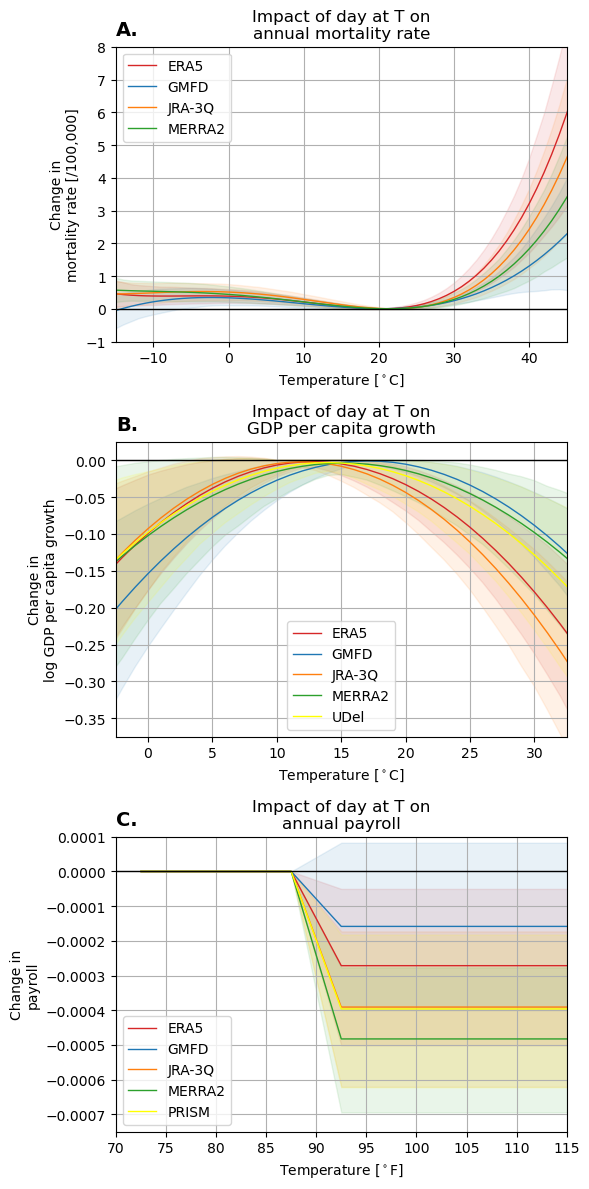

In [7]:
save_fig = True
output_fn = dir_list['figs']+'Figure1'

fig = plt.figure(figsize=(6,12))
proclist = ['mortality','gdppc','payroll']

for plt_idx,proc in enumerate(proclist):
    dmgf = load_dmgfs(proc)

    ax = plt.subplot(len(proclist),1,plt_idx+1)

    ax = plot_dmgfs(dmgf,proc,ax=ax)

    ax.annotate(string.ascii_uppercase[plt_idx]+'.',(0,1.025),xycoords = 'axes fraction',
                va = 'bottom',fontweight='bold',fontsize=14)

    ax.legend()

    if proc in ['mortality','gdppc']:
        ax.set_xlabel(r'Temperature [$^\circ$C]')
    elif proc in ['payroll']:
        ax.set_xlabel(r'Temperature [$^\circ$F]')

plt.tight_layout()

if save_fig:
    utility_print(output_fn)

## Version comparing different proc-specific configurations

e.g., "allyears" vs. "post1980" for GDP pc. 

Structure: 

- Multicolumn, with the first column being the main text figure, and subsequent columns showing different other configurations, maybe with a textbox in each subplot explaining what's up (with ylabel impact variable labels)

/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/dmgfs_byspecification.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/dmgfs_byspecification.png saved!


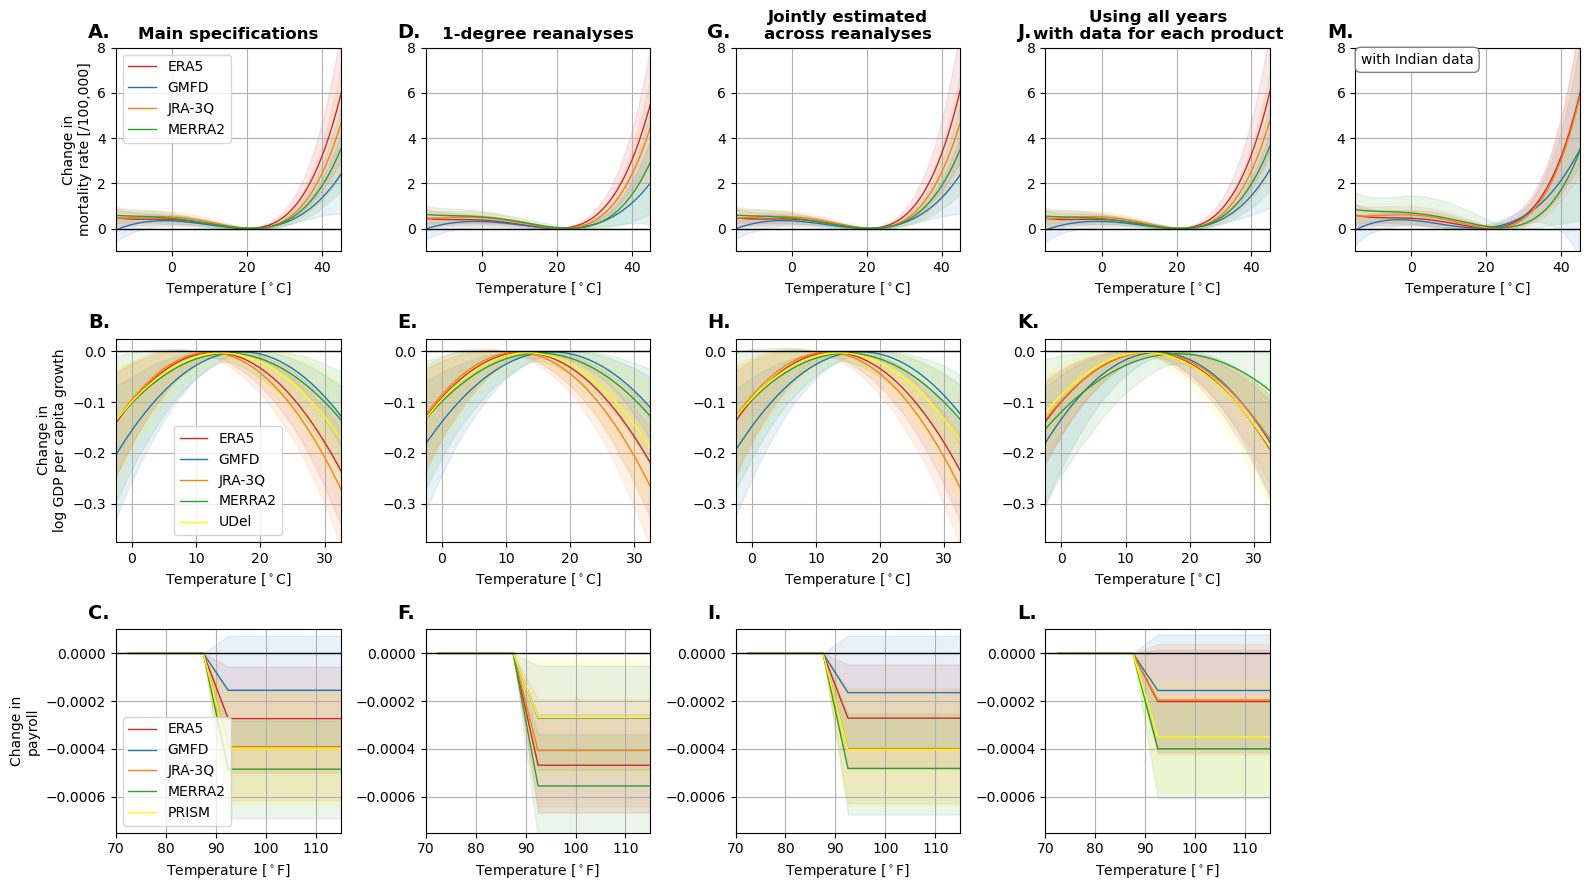

In [8]:
save_fig = True
output_fn = f'{dir_list['figs']}extra_figs/dmgfs_byspecification'

fig = plt.figure(figsize=(16,9))

proclist = ['mortality','gdppc','payroll']

coldicts = [{'resolution':'025deg'},
            {'resolution':'1deg'},
            {'obstreat':'joint','joint_':True},
            {'timeframe':'ALLYEARS'},
            {'mortality':{'indflag':'wInd'}}]
collabels = ['Main specifications',
             '1-degree reanalyses',
             'Jointly estimated\nacross reanalyses',
             'Using all years\nwith data for each product',
             {'mortality':'with Indian data'}]
             
plt_idx = 0
for col_idx,colparams in enumerate(coldicts):
    for row_idx,proc in enumerate(proclist):
        if np.any([k in colparams for k in proclist]):
            if proc in colparams:
                dmgf = load_dmgfs(proc,load_kwargs = colparams[proc])
            else:
                continue
        else:
            dmgf = load_dmgfs(proc,load_kwargs = colparams)
            
        ax = plt.subplot(len(proclist),len(coldicts),(row_idx*len(coldicts))+1+col_idx)
    
        ax = plot_dmgfs(dmgf,proc,ax=ax)
    
        ax.annotate(string.ascii_uppercase[plt_idx]+'.',(-0.125,1.03),xycoords = 'axes fraction',
                    va = 'bottom',fontweight='bold',fontsize=14)
        plt_idx += 1

        if col_idx == 0:
            ax.legend()
    
        if proc in ['mortality','gdppc']:
            ax.set_xlabel(r'Temperature [$^\circ$C]')
        elif proc in ['payroll']:
            ax.set_xlabel(r'Temperature [$^\circ$F]')

        if col_idx > 0:
            ax.set_ylabel('')

        if proc in collabels[col_idx]:
            ax.annotate(collabels[col_idx][proc],
                        (0.025,0.975),xycoords = 'axes fraction',
                        ha='left',va='top',bbox={'boxstyle':'round,pad=0.4','fc':'white','ec':'grey'})
            ax.set_title('')
        else:
            if row_idx == 0:
                ax.set_title(collabels[col_idx],fontweight='bold')
            else:
                ax.set_title('')
            
                        
    
    plt.tight_layout()

if save_fig:
    utility_print(output_fn)